In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/SentimentForge"

print("Project directory exists:", os.path.exists(PROJECT_DIR))
print("Project files:", os.listdir(PROJECT_DIR))

Project directory exists: True
Project files: ['models', 'data', '.ipynb_checkpoints']


In [ ]:
import pandas as pd

DATA_PATH = "/content/IMDB Dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (50000, 2)
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


In [ ]:
import re
import numpy as np
import pandas as pd

from bs4 import BeautifulSoup
from sklearn.model_selection import train_test_split

def clean_review(text):
    text = BeautifulSoup(text, "html.parser").get_text(" ")
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].apply(clean_review)

df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print(df[["clean_review", "label"]].head())

                                        clean_review  label
0  one of the other reviewers has mentioned that ...      1
1  a wonderful little production the filming tech...      1
2  i thought this was a wonderful way to spend ti...      1
3  basically there's a family where a little boy ...      0
4  petter mattei's love in the time of money is a...      1


In [ ]:
X = df["clean_review"]
y = df["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (40000,)
Validation: (5000,)
Testing: (5000,)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float32
)

# Learn vocabulary and calculate TF-IDF on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and test using the same vocabulary
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training matrix: (40000, 50000)
Validation matrix: (5000, 50000)
Testing matrix: (5000, 50000)
Vocabulary size: 50000


In [ ]:
print("Matrix type:", type(X_train_tfidf))

print("Matrix shape:", X_train_tfidf.shape)

print("Non-zero values:", X_train_tfidf.nnz)

total_values = (
    X_train_tfidf.shape[0] *
    X_train_tfidf.shape[1]
)

sparsity = (
    1 - X_train_tfidf.nnz / total_values
) * 100

print("Sparsity:", round(sparsity, 2), "%")

print(
    "Memory used (MB):",
    round(
        (X_train_tfidf.data.nbytes +
         X_train_tfidf.indices.nbytes +
         X_train_tfidf.indptr.nbytes) / (1024**2),
        2
    )
)

Matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Matrix shape: (40000, 50000)
Non-zero values: 9448214
Sparsity: 99.53 %
Memory used (MB): 72.24


In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    C=1.0,
    max_iter=1000,
    solver="liblinear",
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_val_pred = lr_model.predict(X_val_tfidf)

y_val_prob = lr_model.predict_proba(X_val_tfidf)[:, 1]

print("Validation Results")
print("-------------------")

print("Accuracy:", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred))
print("Recall:", recall_score(y_val, y_val_pred))
print("F1 Score:", f1_score(y_val, y_val_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob))

Validation Results
-------------------
Accuracy: 0.9068
Precision: 0.8963367108339828
Recall: 0.92
F1 Score: 0.9080142123963679
ROC-AUC: 0.9702316799999999


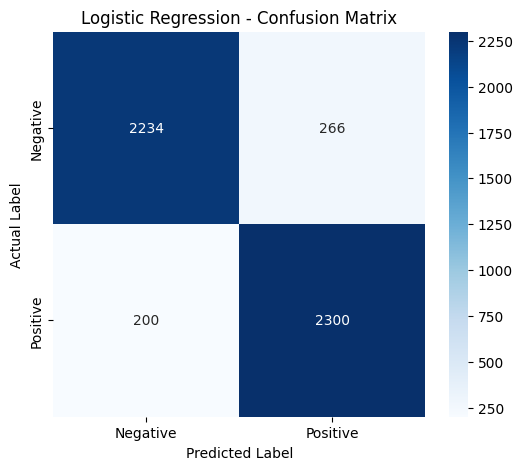

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

In [ ]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB(alpha=1.0)

# Train
nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes training completed!")

Naive Bayes training completed!


In [ ]:
y_val_pred_nb = nb_model.predict(X_val_tfidf)

y_val_prob_nb = nb_model.predict_proba(X_val_tfidf)[:, 1]

print("Naive Bayes Validation Results")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_val, y_val_pred_nb))
print("Precision:", precision_score(y_val, y_val_pred_nb))
print("Recall:", recall_score(y_val, y_val_pred_nb))
print("F1 Score:", f1_score(y_val, y_val_pred_nb))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_nb))

Naive Bayes Validation Results
--------------------------------
Accuracy: 0.8834
Precision: 0.8733930658356057
Recall: 0.8968
F1 Score: 0.8849417801460431
ROC-AUC: 0.9528932800000001


In [ ]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Multinomial Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_val, y_val_pred),
        accuracy_score(y_val, y_val_pred_nb)
    ],
    "Precision": [
        precision_score(y_val, y_val_pred),
        precision_score(y_val, y_val_pred_nb)
    ],
    "Recall": [
        recall_score(y_val, y_val_pred),
        recall_score(y_val, y_val_pred_nb)
    ],
    "F1 Score": [
        f1_score(y_val, y_val_pred),
        f1_score(y_val, y_val_pred_nb)
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, y_val_prob),
        roc_auc_score(y_val, y_val_prob_nb)
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9068,0.8963,0.9200,0.9080,0.9702
1,Multinomial Naive Bayes,0.8834,0.8734,0.8968,0.8849,0.9529


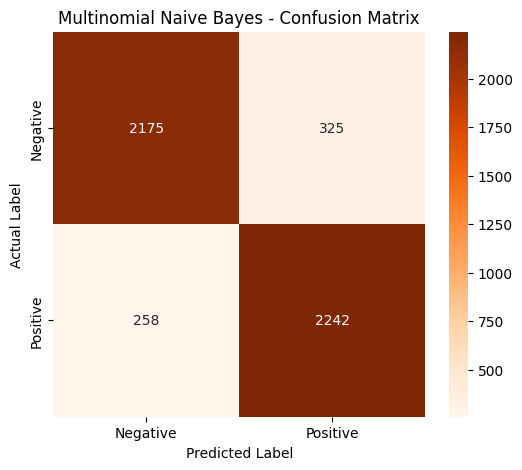

In [ ]:
cm_nb = confusion_matrix(y_val, y_val_pred_nb)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Multinomial Naive Bayes - Confusion Matrix")

plt.show()

In [ ]:
# Create a validation prediction report

val_results = pd.DataFrame({
    "review": X_val,
    "actual": y_val,
    "predicted": y_val_pred,
    "positive_probability": y_val_prob
})

# Identify incorrect predictions
errors = val_results[
    val_results["actual"] != val_results["predicted"]
].copy()

# Categorize the errors
errors["error_type"] = np.where(
    errors["actual"] == 0,
    "False Positive",
    "False Negative"
)

print("Total errors:", len(errors))

print("\nError distribution:")
print(errors["error_type"].value_counts())

Total errors: 466

Error distribution:
error_type
False Positive    266
False Negative    200
Name: count, dtype: int64


In [ ]:
# False Positives
print("FALSE POSITIVES")
display(
    errors[errors["error_type"] == "False Positive"]
    [["review", "positive_probability"]]
    .head(5)
)

# False Negatives
print("FALSE NEGATIVES")
display(
    errors[errors["error_type"] == "False Negative"]
    [["review", "positive_probability"]]
    .head(5)
)

FALSE POSITIVES


,review,positive_probability
28906,i being of puertorican descent had mixed filli...,0.556562
35438,matt cordell is back from the dead for a third...,0.569817
39589,this movie basks too much in its own innocence...,0.671058
45541,what's with indonesian musical movies never ha...,0.518558
44849,tim robbins is oddly benign here cast as a gar...,0.777313


FALSE NEGATIVES


,review,positive_probability
28288,i've never seen a bollywood film before but i ...,0.428510
18142,i saw this movie when it first came out patty ...,0.309927
36440,a pleasant surprise i expected a further downg...,0.391282
20132,pretty amusing spoof with great attention to d...,0.404146
36583,don't change your husband is another soap oper...,0.490966


In [ ]:
pd.set_option("display.max_colwidth", None)

print("FALSE POSITIVES")

display(
    errors[errors["error_type"] == "False Positive"]
    [["review", "actual", "predicted", "positive_probability"]]
    .head(3)
)

print("\nFALSE NEGATIVES")

display(
    errors[errors["error_type"] == "False Negative"]
    [["review", "actual", "predicted", "positive_probability"]]
    .head(3)
)

FALSE POSITIVES


,review,actual,predicted,positive_probability
28906,i being of puertorican descent had mixed fillings about this documentary first i was offended that ms perez compared senor campos to che guevarra also just a point of fact mr john leguzaimo is not of puertorican descent his parents came from columbia whomever did research on this was not very accurate i feel that the future of our race rests on education this message should have been resounding throughout this film education is our road to freedom and power i think any future endeavors of this production team should make this their focus in my opinion this film swayed toward an anti american sentiment,0,1,0.556562
35438,matt cordell is back from the dead for a third go round although i'm not sure anyone cared at this point except for rabid manica cop fans cordell who died in the last flick is resurrected through voodoo and is now hot on the trail of several miscreants involved in the shooting of a fellow officer cordell is very fond of i missed part of this early ' s low budget quickie but it was pleasing to see cordell wracking up the body count in various gruesome ways problem is the overall film is pretty static and cordell simply ain't jason or freddy the interest wanes pretty fast even with that grand b movie master robert forster as a doctor who ends up with his brains scrambled stick with the first film in the series which is funny and scary and exciting all at the same time,0,1,0.569817
39589,this movie basks too much in its own innocence it doesn't tell a story it's more a big time snooze fest while the actors are all personable the story is so trite and goes nowhere i think victor rasuk has great charisma but deserves a real film from a real storyteller,0,1,0.671058



FALSE NEGATIVES


,review,actual,predicted,positive_probability
28288,i've never seen a bollywood film before but i caught the first ten minutes of this laughed myself silly and hit the r button on sky i'm glad i did i hope i don't insult anybody because basically the bf and i loved it but we couldn't take it half as seriously as the actors did especially the obsessed one who i understand is a huge bollywood star because we've seen him on the cover of lots of dvds since and i even saw a doll of him today in hamleys the bf keeps on about this bloke i am beginning to think he's obsessed he keeps saying that it's strange for the traditionally good looking one to be the anti hero of a film but then we do like films that aren't your stock predictable hollywood fare it was completely over the top but really good fun if all bollywood films are like this then we're watching more i have had that bloomin' song in my head all week and i can't speak a word of hindi ps any recommendations would be appreciated,1,0,0.428510
18142,i saw this movie when it first came out patty didn't want to be separated from her siblings however the juvenile justice system don't care when patty looked at the case file the judge sent her to a juvenile detention facility he claimed she violated the rules of privacy by looking at private files she just wanted her family together i couldn't blame her the parents were not even fit parents one of the smaller children had to have a restroom the father stopped and let them off he drove off him and left the children stranded at the service station patty had to take authority to protect them since she was the oldest they were placed in foster homes the good part is that the social worker got them back as a family the head social worker kept telling him to butt out and not interfere he was power crazy he was the one who had patty placed in the juvenile facility why didn't they go after the father who was released from prison for abandonment yet the children are caught in the middle and made to feel insecure,1,0,0.309927
36440,a pleasant surprise i expected a further downgrade along the line the rock con air armaggeddon especially for such an overhyped film perhaps that's the reason so few approved of this new type of bruckheimer fare clever dialogue instead of snappy one liners decent background motivation instead of shake n bake stereotypes and when the chase came you really thirsted for it fanboys expecting an armageddon rollercoaster stay away this is one for the more intelligent action fans it didn't even bother me jolie appeared so little,1,0,0.391282


In [ ]:
import os
import joblib

MODEL_DIR = "/content/drive/MyDrive/SentimentForge/models"

os.makedirs(MODEL_DIR, exist_ok=True)

# Save trained Logistic Regression model
joblib.dump(
    lr_model,
    os.path.join(MODEL_DIR, "logistic_regression.pkl")
)

# Save fitted TF-IDF vectorizer
joblib.dump(
    tfidf,
    os.path.join(MODEL_DIR, "tfidf_vectorizer.pkl")
)

print("Models saved successfully!")

Models saved successfully!


In [ ]:
print(os.listdir(MODEL_DIR))

['tokenizer.pkl', 'preprocessing_config.json', 'logistic_regression.pkl', 'tfidf_vectorizer.pkl']


In [ ]:
loaded_model = joblib.load(
    os.path.join(MODEL_DIR, "logistic_regression.pkl")
)

loaded_vectorizer = joblib.load(
    os.path.join(MODEL_DIR, "tfidf_vectorizer.pkl")
)

sample_review = "This movie was absolutely fantastic and entertaining!"

cleaned = clean_review(sample_review)

sample_features = loaded_vectorizer.transform([cleaned])

prediction = loaded_model.predict(sample_features)[0]
probability = loaded_model.predict_proba(sample_features)[0]

print("Prediction:", "Positive" if prediction == 1 else "Negative")
print("Negative probability:", round(probability[0], 4))
print("Positive probability:", round(probability[1], 4))

Prediction: Positive
Negative probability: 0.1419
Positive probability: 0.8581


In [ ]:
import os
import pandas as pd

# Create reports directory if it doesn't exist
REPORT_DIR = "/content/drive/MyDrive/SentimentForge/reports"
os.makedirs(REPORT_DIR, exist_ok=True)

# Validation results
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.9068,
        "Precision": 0.8963,
        "Recall": 0.9200,
        "F1_Score": 0.9080,
        "ROC_AUC": 0.9702
    },
    {
        "Model": "Multinomial Naive Bayes",
        "Accuracy": 0.8834,
        "Precision": 0.8734,
        "Recall": 0.8968,
        "F1_Score": 0.8849,
        "ROC_AUC": 0.9529
    }
])

# Save results
results.to_csv(
    os.path.join(REPORT_DIR, "experiment_results.csv"),
    index=False
)

print("Experiment results saved successfully!")
print(results)

Experiment results saved successfully!
                     Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC
0      Logistic Regression    0.9068     0.8963  0.9200    0.9080   0.9702
1  Multinomial Naive Bayes    0.8834     0.8734  0.8968    0.8849   0.9529


In [ ]:
print(os.listdir(REPORT_DIR))

['experiment_results.csv']
